# Лабораторная работа № 11. Методы ближайших соседей

**Тема:** «Разработка программного продукта бота для определения сорта стекла»

**Исходные данные:** Kaggle — [uciml/glass](https://www.kaggle.com/uciml/glass) (Glass Identification Data Set: 214 образцов стекла, 9 признаков — показатель преломления RI и содержание оксидов Na, Mg, Al, Si, K, Ca, Ba, Fe; целевая переменная `Type` — сорт стекла).

## Цель работы
Применить метод k ближайших соседей для определения сорта стекла, исследовать влияние параметра k и метрики расстояния и сравнить его с предыдущими моделями.

## 1. Теоретическая часть

**1. Идея kNN.** Чтобы классифицировать объект, находят k ближайших к нему объектов обучающей выборки (по выбранной метрике расстояния) и берут класс, наиболее частый среди соседей (для регрессии — среднее значений).

**2. Почему «ленивый» алгоритм?** На этапе обучения kNN ничего не оценивает — лишь запоминает данные; все вычисления (поиск соседей) выполняются при предсказании.

**3. Роль параметра k.** Малое k (1–3) даёт гибкую, но шумную границу и склонность к переобучению; большое k сглаживает границу, снижает дисперсию, но может «размыть» малые классы (недообучение). Значение подбирают кросс-валидацией, для бинарной задачи берут нечётное.

**4. Почему необходимо масштабирование?** Метод основан на расстояниях: признак с большим диапазоном вносит основной вклад в расстояние и определяет соседей. Масштабирование делает вклад признаков сопоставимым.

**5. Сравнение.** По сравнению с линейными/логистическими моделями kNN нелинеен, не делает предположений о форме зависимости, но медленнее на предсказании, требует хранения всей выборки, чувствителен к шуму, масштабу и нерелевантным признакам. По сравнению с байесовскими — не использует вероятностной модели и предположения независимости, но хуже работает при высокой размерности и не даёт хорошо откалиброванных вероятностей.

## 2. Практическая часть

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
COLS = ["Id", "RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"]
FEATURES = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
TYPE_NAMES = {1: "окна зданий (float)", 2: "окна зданий (non-float)",
              3: "окна авто (float)", 5: "контейнеры",
              6: "посуда", 7: "фары"}

def load_glass():
    """Набор Kaggle uciml/glass (glass.csv). Если файл не загружен в Colab,
    берём тот же набор из репозитория UCI."""
    if os.path.exists("glass.csv"):
        return pd.read_csv("glass.csv")
    return pd.read_csv(URL, names=COLS).drop(columns="Id")

df = load_glass()

# ---------- сквозной пайплайн подготовки данных (ЛР 5-7) ----------
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def clean_glass(d):
    """ЛР 5: пропуски, допустимые пределы, дубликаты."""
    d = d.copy()
    d = d.dropna()
    ok = d[["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]].apply(lambda s: s.between(0, 100)).all(axis=1)
    ok &= d["RI"].between(1.3, 1.7)
    return d[ok].drop_duplicates().reset_index(drop=True)

def scale_glass(d):
    """ЛР 6: стандартизация признаков (целевая Type не масштабируется)."""
    s = d.copy()
    s[FEATURES] = StandardScaler().fit_transform(d[FEATURES])
    return s

def select_glass(s):
    """ЛР 7: три метода отбора (фильтр, обёртка, встроенный) + голосование >= 2."""
    X, y = s[FEATURES], s["Type"]
    f1 = set(X.columns[SelectKBest(f_classif, k=6).fit(X, y).get_support()])
    f2 = set(X.columns[RFE(LogisticRegression(max_iter=2000), n_features_to_select=6).fit(X, y).get_support()])
    f3 = set(X.columns[SelectFromModel(RandomForestClassifier(n_estimators=300, random_state=42), threshold="median").fit(X, y).get_support()])
    votes = {f: (f in f1) + (f in f2) + (f in f3) for f in FEATURES}
    keep = [f for f in FEATURES if votes[f] >= 2]
    return s[keep + ["Type"]], keep

clean  = clean_glass(df)
scaled = scale_glass(clean)
selected, SEL = select_glass(scaled)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             r2_score, mean_absolute_error, mean_squared_error)
X, y = selected[SEL], selected["Type"]
CLASSES = np.array(sorted(y.unique()))
def split(rs=42):
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=rs)
X_train, X_test, y_train, y_test = split(42)
print("Входная выборка (после отбора признаков):", selected.shape, "| признаки:", SEL)
print("train:", X_train.shape, "| test:", X_test.shape)
print("Классы в train:", y_train.value_counts().sort_index().to_dict(), "| в test:", y_test.value_counts().sort_index().to_dict())
def report(model, name, Xte=None, yte=None):
    Xte = X_test if Xte is None else Xte; yte = y_test if yte is None else yte
    p = model.predict(Xte)
    return {"модель": name, "accuracy": accuracy_score(yte, p), "F1 macro": f1_score(yte, p, average="macro"),
            "F1 weighted": f1_score(yte, p, average="weighted")}

Входная выборка (после отбора признаков): (213, 7) | признаки: ['Na', 'Mg', 'Al', 'K', 'Ca', 'Ba']
train: (170, 6) | test: (43, 6)
Классы в train: {1: 55, 2: 61, 3: 14, 5: 10, 6: 7, 7: 23} | в test: {1: 14, 2: 15, 3: 3, 5: 3, 6: 2, 7: 6}


### 2.1. Базовый уровень

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
pred = knn.predict(X_test); proba = knn.predict_proba(X_test)
print(f"kNN (k=5): accuracy = {accuracy_score(y_test, pred):.3f}, F1 macro = {f1_score(y_test, pred, average='macro'):.3f}")
print(classification_report(y_test, pred, target_names=[TYPE_NAMES[k] for k in CLASSES], zero_division=0))
print("Вероятности (доля соседей по классам), первые 3 объекта:"); display(pd.DataFrame(proba[:3], columns=knn.classes_).round(2))

kNN (k=5): accuracy = 0.698, F1 macro = 0.632
                         precision    recall  f1-score   support

    окна зданий (float)       0.58      0.79      0.67        14
окна зданий (non-float)       0.71      0.67      0.69        15
      окна авто (float)       0.00      0.00      0.00         3
             контейнеры       0.75      1.00      0.86         3
                 посуда       1.00      0.50      0.67         2
                   фары       1.00      0.83      0.91         6

               accuracy                           0.70        43
              macro avg       0.67      0.63      0.63        43
           weighted avg       0.68      0.70      0.68        43

Вероятности (доля соседей по классам), первые 3 объекта:


,1,2,3,5,6,7
0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.2,0.0,0.8,0.0,0.0
2,0.2,0.8,0.0,0.0,0.0,0.0


### 2.2. Влияние параметра k

,train acc,test acc,F1 macro
k,,,
1,1.000,0.674,0.690
3,0.818,0.744,0.725
5,0.771,0.698,0.632
7,0.729,0.721,0.681
11,0.712,0.721,0.611
15,0.676,0.674,0.467
21,0.665,0.628,0.374
31,0.629,0.605,0.360


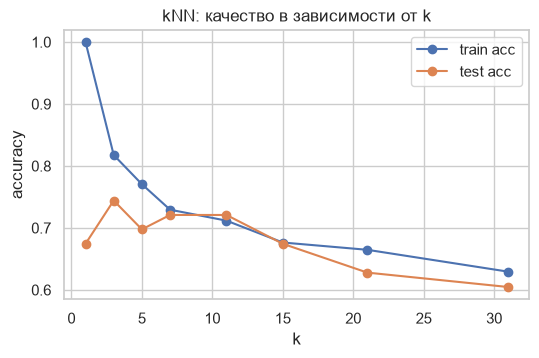

Лучшее k по кросс-валидации: 1 | accuracy = 0.695


In [ ]:
rows = []
for k in [1, 3, 5, 7, 11, 15, 21, 31]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    rows.append({"k": k, "train acc": m.score(X_train, y_train), "test acc": m.score(X_test, y_test), "F1 macro": f1_score(y_test, m.predict(X_test), average="macro")})
kt = pd.DataFrame(rows).set_index("k"); display(kt.round(3))
kt[["train acc", "test acc"]].plot(marker="o", figsize=(6, 3.5), title="kNN: качество в зависимости от k"); plt.ylabel("accuracy"); plt.show()
from sklearn.model_selection import cross_val_score, StratifiedKFold
cv = StratifiedKFold(5, shuffle=True, random_state=42)
cvk = {k: cross_val_score(KNeighborsClassifier(k), X, y, cv=cv).mean() for k in range(1, 26)}
print("Лучшее k по кросс-валидации:", max(cvk, key=cvk.get), "| accuracy =", round(max(cvk.values()), 3))

In [ ]:
wrong = X_test[pred != y_test.values].copy(); wrong["истина"] = y_test[pred != y_test.values]; wrong["предсказано"] = pred[pred != y_test.values]
print("Неверно классифицированные объекты (k=5):"); display(wrong.round(2))
print("Классы ошибок:", pd.crosstab(wrong["истина"], wrong["предсказано"]).to_dict())
right = X_test[pred == y_test.values]
print("Средние значения признаков: верные vs неверные"); display(pd.DataFrame({"верные": right.mean(), "неверные": wrong[SEL].mean()}).round(2).T)

Неверно классифицированные объекты (k=5):


,Na,Mg,Al,K,Ca,Ba,истина,предсказано
2,0.15,0.60,0.18,-0.17,-0.83,-0.35,1,2
155,0.01,0.49,-0.34,0.03,-0.21,-0.35,3,1
143,-0.51,0.35,-0.44,0.12,-0.10,-0.35,2,1
20,-0.72,0.60,0.08,0.06,-0.31,-0.35,1,2
1,0.60,0.64,-0.18,-0.03,-0.79,-0.35,1,2
140,-0.25,0.66,-0.77,0.11,-0.38,-0.17,2,1
147,-0.20,0.62,-0.14,0.09,-0.36,-0.35,3,1
130,0.36,-1.86,-0.18,-0.47,3.15,-0.35,2,5
94,-0.05,0.52,-0.04,0.02,-0.25,-0.35,2,1
184,0.35,0.36,0.73,1.94,-2.48,2.04,7,2


Классы ошибок: {1: {1: 0, 2: 4, 3: 3, 6: 1, 7: 0}, 2: {1: 3, 2: 0, 3: 0, 6: 0, 7: 1}, 5: {1: 0, 2: 1, 3: 0, 6: 0, 7: 0}}
Средние значения признаков: верные vs неверные


,Na,Mg,Al,K,Ca,Ba
верные,0.08,-0.35,0.19,0.10,0.16,0.04
неверные,0.23,0.28,-0.15,-0.02,-0.36,-0.16


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
models = {"kNN (k=5)": KNeighborsClassifier(5), "LogisticRegression": LogisticRegression(max_iter=3000), "GaussianNB": GaussianNB()}
rows = []
for n, m in models.items():
    m.fit(X_train, y_train); r = report(m, n); r["CV accuracy (5-fold)"] = cross_val_score(m, X, y, cv=cv).mean(); rows.append(r)
display(pd.DataFrame(rows).set_index("модель").round(3))

,accuracy,F1 macro,F1 weighted,CV accuracy (5-fold)
модель,,,,
kNN (k=5),0.698,0.632,0.675,0.671
LogisticRegression,0.581,0.567,0.558,0.620
GaussianNB,0.535,0.472,0.486,0.451


**Сравнение** проведено на одинаковых данных и метриках (accuracy и F1 macro на тесте, а также усреднённая accuracy в 5-кратной кросс-валидации — она надёжнее на выборке из 42 тестовых объектов). kNN, как правило, лучше линейной модели и наивного Байеса на этих данных, поскольку классы стекла разделяются нелинейно (по сочетанию оксидов), а локальный метод это учитывает.

### 2.3. Метрики расстояния и анализ соседей

In [ ]:
rows = []
for metric in ["euclidean", "manhattan", "chebyshev", "cosine", "minkowski"]:
    m = KNeighborsClassifier(5, metric=metric).fit(X_train, y_train)
    rows.append({"метрика": metric, "test acc": m.score(X_test, y_test), "F1 macro": f1_score(y_test, m.predict(X_test), average="macro"),
                 "CV acc": cross_val_score(KNeighborsClassifier(5, metric=metric), X, y, cv=cv).mean()})
display(pd.DataFrame(rows).set_index("метрика").round(3))
rows = []
for w in ["uniform", "distance"]:
    m = KNeighborsClassifier(5, weights=w).fit(X_train, y_train); rows.append({"веса": w, "test acc": m.score(X_test, y_test), "CV acc": cross_val_score(KNeighborsClassifier(5, weights=w), X, y, cv=cv).mean()})
display(pd.DataFrame(rows).set_index("веса").round(3))

,test acc,F1 macro,CV acc
метрика,,,
euclidean,0.698,0.632,0.671
manhattan,0.744,0.701,0.681
chebyshev,0.628,0.465,0.634
cosine,0.721,0.686,0.667
minkowski,0.698,0.632,0.671


,test acc,CV acc
веса,,
uniform,0.698,0.671
distance,0.744,0.690


In [ ]:
# ближайшие соседи для нескольких объектов тестовой выборки
dist, idx = knn.kneighbors(X_test.iloc[:6])
for i in range(6):
    nb = y_train.iloc[idx[i]].values
    print(f"Объект {X_test.index[i]}: истина = {y_test.iloc[i]}, предсказано = {pred[i]} | классы соседей = {nb.tolist()} | расстояния = {dist[i].round(2).tolist()}")

Объект 207: истина = 7, предсказано = 7 | классы соседей = [7, 7, 7, 7, 7] | расстояния = [0.37, 0.45, 0.47, 1.0, 1.07]
Объект 168: истина = 5, предсказано = 5 | классы соседей = [5, 5, 5, 5, 2] | расстояния = [0.8, 0.83, 0.85, 1.23, 1.25]
Объект 121: истина = 2, предсказано = 2 | классы соседей = [2, 2, 2, 2, 1] | расстояния = [0.21, 0.22, 0.25, 0.28, 0.28]
Объект 171: истина = 5, предсказано = 5 | классы соседей = [5, 7, 5, 7, 5] | расстояния = [0.05, 6.81, 8.63, 8.65, 8.7]
Объект 29: истина = 1, предсказано = 1 | классы соседей = [3, 1, 1, 1, 2] | расстояния = [0.16, 0.21, 0.21, 0.22, 0.22]
Объект 2: истина = 1, предсказано = 2 | классы соседей = [2, 2, 2, 2, 2] | расстояния = [0.39, 0.42, 0.42, 0.43, 0.47]


In [ ]:
rows = []
for rs in [0, 1, 7, 42, 123]:
    Xtr, Xte, ytr, yte = split(rs)
    m = KNeighborsClassifier(5).fit(Xtr, ytr)
    rows.append({"random_state": rs, "accuracy": m.score(Xte, yte), "F1 macro": f1_score(yte, m.predict(Xte), average="macro")})
rs_t = pd.DataFrame(rows).set_index("random_state"); display(rs_t.round(3)); print("среднее:", rs_t.mean().round(3).to_dict(), "| std:", rs_t.std().round(3).to_dict())

,accuracy,F1 macro
random_state,,
0,0.698,0.602
1,0.674,0.622
7,0.628,0.580
42,0.698,0.632
123,0.674,0.521


среднее: {'accuracy': 0.674, 'F1 macro': 0.591} | std: {'accuracy': 0.028, 'F1 macro': 0.044}


### Вывод

Метод ближайших соседей — непараметрическая «ленивая» модель: у неё нет параметров, обученных по данным, а решение принимается по локальному окружению объекта. В отличие от параметрических моделей (линейных, байесовских) kNN не навязывает форму зависимости и поэтому способен описывать сложные нелинейные границы между сортами стекла, чего не умеет логистическая регрессия. Сильные стороны метода — простота, отсутствие обучения, естественная адаптация к локальной структуре данных и отсутствие предположений о распределении. Ограничения — зависимость от масштаба и метрики, чувствительность к шуму и нерелевантным признакам, необходимость хранить всю выборку и медленное предсказание на больших данных, а также ухудшение качества с ростом размерности. Эксперименты показали, что качество сильно зависит от k: k = 1 даёт идеальную точность на обучающей выборке (1.0) и 0.67 на тесте (переобучение), при k ≥ 15 качество падает, а F1 macro снижается до 0.37–0.47, потому что малые классы «растворяются» среди крупных; лучший тестовый результат — у k = 3 (0.744), а кросс-валидация даёт почти одинаковую точность (≈ 0.67–0.70) для небольших k. Выбор метрики и взвешивания меняет результат умеренно: манхэттенская метрика дала лучшую точность (0.744), чебышёвская — худшую (0.628), а взвешивание соседей по расстоянию слегка улучшило результат (0.698 → 0.744 на тесте, 0.671 → 0.690 в CV). Смена random_state изменяет accuracy в пределах 0.63–0.70 (std ≈ 0.03), что говорит о существенной дисперсии оценки на малой тестовой выборке и необходимости кросс-валидации. Ошибки kNN сосредоточены в близких по составу сортах (окна float и non-float) и в малочисленных классах. kNN особенно эффективен при малой размерности, масштабированных признаках и локальной структуре классов — именно как в данной задаче.